In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os

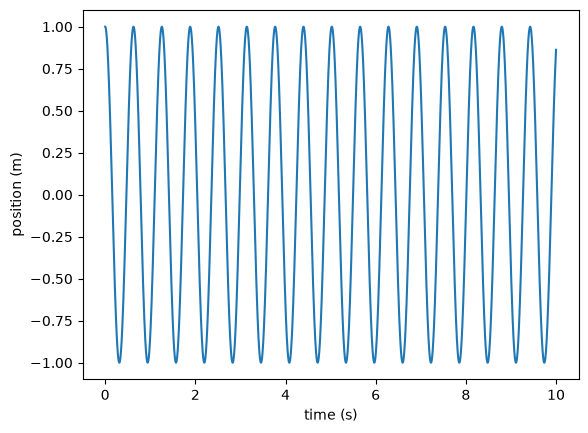

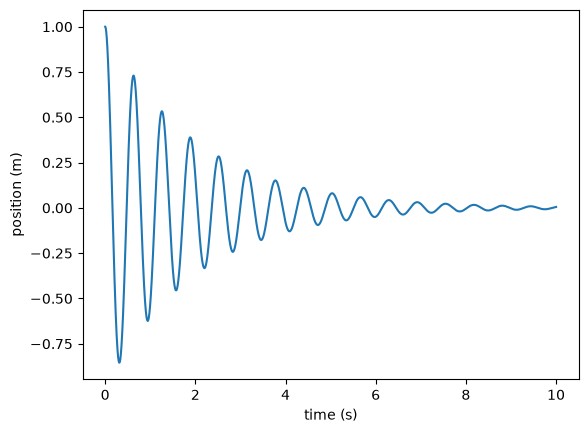

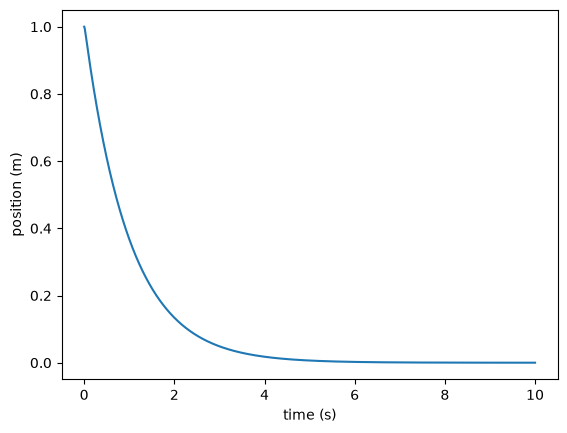

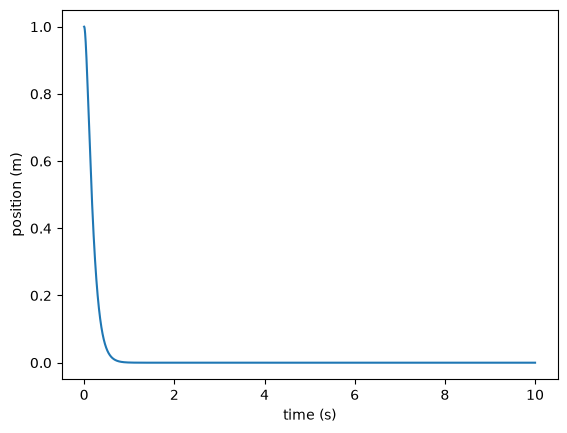

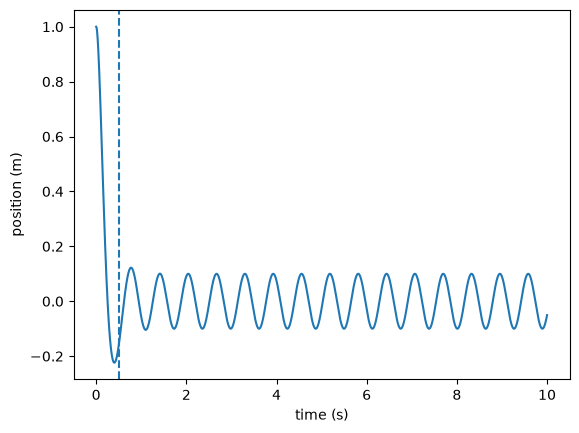

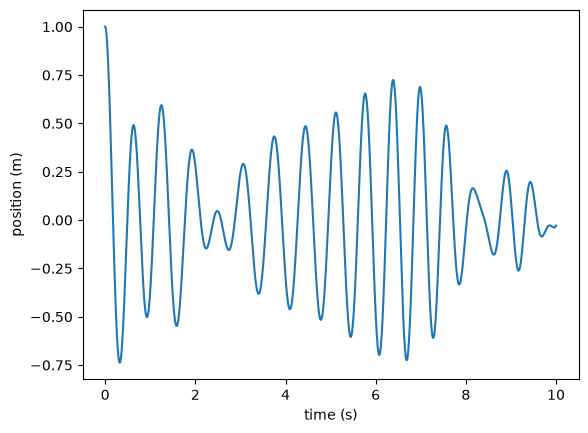

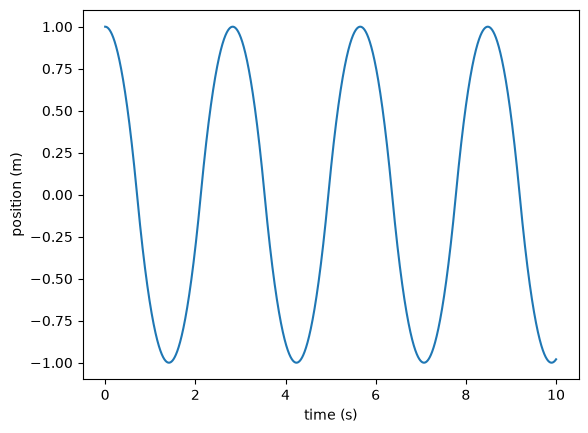

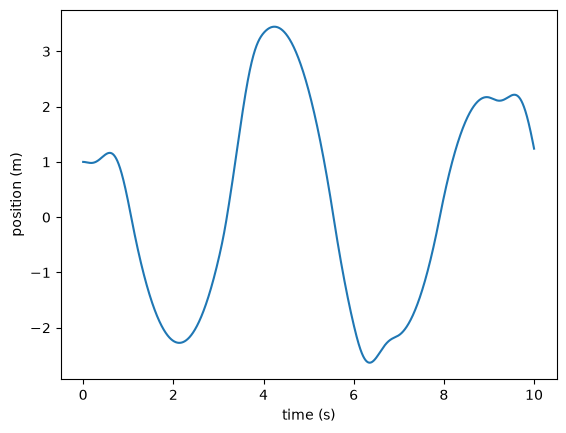

In [10]:
nsteps=100000

def euler(force, times, x0, v0, m,dt):

    x = np.zeros(nsteps)
    v = np.zeros(nsteps)
    x[0]=x0
    v[0]=v0

    for i in range(nsteps-1):
        a = force(times[i], x[i], v[i]) / m
        v[i+1] = v[i] + a*dt
        x[i+1] = x[i] + v[i+1]*dt
    return x, v
    
times,dt = np.linspace(0, 10, nsteps,retstep=True)


x0 = 1
v0 = 0
m = 1
k = 100
f = 10
w0 = np.sqrt(k/m)

wdstart = w0 - 5
wdend = w0 + 5
timemax = times[-1]
sweep = (wdend - wdstart) / timemax



def restorative(t,x,v):
    return -k*x

def underdamped(t,x,v):
    b = 1
    return -k*x-b*v

def overdamped(t,x,v):
    b = 100
    return -k*x-b*v

def criticallydamped(t,x,v):
    b = 20
    return -k*x-b*v

def fforce(t,x,v):
    b = 10
    return -k*x-b*v+f*np.cos(w0*t)

def sweepforce(t,x,v):
    b = 1
    phase = wdstart*t + 0.5*sweep*(t**2)
    return -k*x-b*v+f*np.cos(phase)



f0 = 4
fdrive = 8
period = 3
window = 1


def freeportion(t,x,v):
    if x > 0:
        return -f0
    elif x < 0:
        return f0
    else:
        return 0

def forcedportion(t,x,v):
    ftotal = freeportion(t,x,v)
    trelative = t % period
    if trelative < window:
        ftotal += fdrive*np.sin(2*np.pi*trelative/window)
    return ftotal
    


reg,rv = euler(restorative, times, x0, v0, m,dt)
under,uv = euler(underdamped,times,x0,v0,m,dt)
over,ov = euler(overdamped,times,x0,v0,m,dt)
crit,cv = euler(criticallydamped,times,x0,v0,m,dt)
force,fv = euler(fforce,times,x0,v0,m,dt)
sweep,sv = euler(sweepforce,times,x0,v0,m,dt)
free,ev = euler(freeportion,times,x0,v0,m,dt)
forced,dv = euler(forcedportion,times,x0,v0,m,dt)


plt.plot(times,reg)
plt.xlabel("time (s)")
plt.ylabel("position (m)")
plt.show()

#underdamped
plt.plot(times,under)
plt.xlabel("time (s)")
plt.ylabel("position (m)")
plt.show()

#overdamped
plt.plot(times,over)
plt.xlabel("time (s)")
plt.ylabel("position (m)")
plt.show()

#critically damped
plt.plot(times,crit)
plt.xlabel("time (s)")
plt.ylabel("position (m)")
plt.show()

plt.plot(times,force)
plt.xlabel("time (s)")
plt.ylabel("position (m)")
plt.axvline(.5,ls="dashed")
plt.show()

#frequency sweep
plt.plot(times,sweep)
plt.xlabel("time (s)")
plt.ylabel("position (m)")
plt.show()

#free
plt.plot(times,free)
plt.xlabel("time (s)")
plt.ylabel("position (m)")
plt.show()

#forced
plt.plot(times,forced)
plt.xlabel("time (s)")
plt.ylabel("position (m)")
plt.show()


Compared to the graph showing the free motion, the forced motion graph has distortion in some areas. This is probably happening whenever the mass is being subject to forced motion like a push.